# Análisis Exploratorio de Datos (EDA) — Daily Movement Report Anonimizado

**Fuente:** `Daily Movement Report Anonimizado.csv` (reporte de movimientos diarios de flota, telemetría de viajes).

**Contenido del notebook**
1. Configuración y carga de datos
2. Inspección inicial y calidad de datos
3. Limpieza y variables derivadas
4. Estadísticas descriptivas (numéricas y categóricas)
5. Outliers y consistencia de los datos
6. Visualización de datos
7. Hallazgos principales
8. Versiones del entorno para MLOps (celda final)

> **Nota de privacidad:** El archivo usado ya está anonimizado: los vehículos se identifican como VH-01 a VH-05 y los conductores como Conductor 01 a Conductor 20. Los códigos internos de la plataforma no se usan.

## 1. Configuración y carga de datos

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

NOMBRE_CSV = "Daily Movement Report Anonimizado.csv"

RUTAS_POSIBLES = [Path("../data") / NOMBRE_CSV,Path("data") / NOMBRE_CSV,]      # notebook ejecutado desde la raíz del repo


DATA_PATH = next((p for p in RUTAS_POSIBLES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"No se encontró '{NOMBRE_CSV}'. Revisa que esté en data/ "
        "(si usan DVC, ejecuta `dvc pull`)."
    )
print("Usando archivo:", DATA_PATH)

Usando archivo: ../data/Daily Movement Report Anonimizado.csv


In [2]:
# 'utf-8-sig' elimina el BOM que trae el archivo al inicio
dataframe = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
print(f"Filas: {dataframe.shape[0]:,} | Columnas: {dataframe.shape[1]}")
dataframe.head()

Filas: 9,589 | Columnas: 29


,AssetExtra,AssetHostID,AssetID,SiteName,DepartureDate,AssetName2,AssetExtra2,DepartureTime,TimeZone1,DepartFrom,TripType,DrivingTime,StandingTime,Duration,Distance,StartOdoMeter,EndOdoMeter,MaxSpeed,AvgSpeed,ArrivalTime,ArrivalDate,TimeZone2,ArriveAt,NextDepartureDateTime,TimeZone,TimeAtLocation,NrOfVisits,TotalFuelUsedMeasured,CalcFuelConsumption
0,VH-01_Nissan_Frontier_2024,VH-01,2599,la Compañía / Contrato D (Llanos Orientales),22/05/2026,Conductor 01,12326,06:51:27,COT,Llanos Orientales,Descalificado,00:03:36,00:16:12,00:19:48,0.50,"45,795.40","45,795.90",30,8.33,06:55:03,22/05/2026,COT,Llanos Orientales,22/05/2026 07:05,COT,00:10:45,1,1.14,228.00
1,VH-01_Nissan_Frontier_2024,VH-01,2599,la Compañía / Contrato D (Llanos Orientales),22/05/2026,Conductor 01,12326,07:05:48,COT,Llanos Orientales,Descalificado,00:02:28,00:02:09,00:04:37,0.40,"45,795.90","45,796.30",26,9.73,07:08:16,22/05/2026,COT,Llanos Orientales,22/05/2026 07:10,COT,00:02:09,1,0.26,65.50
2,VH-01_Nissan_Frontier_2024,VH-01,2599,la Compañía / Contrato D (Llanos Orientales),22/05/2026,Conductor 01,12326,07:10:25,COT,Llanos Orientales,Descalificado,00:00:42,00:02:05,00:02:47,0.10,"45,796.40","45,796.50",25,8.57,07:11:07,22/05/2026,COT,Llanos Orientales,22/05/2026 07:13,COT,00:02:05,1,0.16,158.00
3,VH-01_Nissan_Frontier_2024,VH-01,2599,la Compañía / Contrato D (Llanos Orientales),22/05/2026,Conductor 01,12326,07:13:12,COT,Llanos Orientales,Descalificado,00:24:08,00:03:29,00:27:37,12.00,"45,796.50","45,808.50",42,29.83,07:37:20,22/05/2026,COT,Llanos Orientales,22/05/2026 07:40,COT,00:03:29,1,1.79,14.88
4,VH-01_Nissan_Frontier_2024,VH-01,2599,la Compañía / Contrato D (Llanos Orientales),22/05/2026,Conductor 01,12326,07:40:49,COT,Llanos Orientales,Descalificado,00:01:08,00:00:14,00:01:22,0.10,"45,808.60","45,808.70",21,5.29,07:41:57,22/05/2026,COT,Llanos Orientales,23/05/2026 13:24,COT,29:42:31,1,0.10,102.00


## 2. Inspección inicial y calidad de datos

In [3]:
resumen = pd.DataFrame({"tipo": dataframe.dtypes.astype(str),"nulos": dataframe.isna().sum(),"% nulos": dataframe.isna().mean() * 100,"únicos": dataframe.nunique(),"ejemplo": dataframe.iloc[0],})
resumen

,tipo,nulos,% nulos,únicos,ejemplo
AssetExtra,object,0,0.00,5,VH-01_Nissan_Frontier_2024
AssetHostID,object,0,0.00,5,VH-01
AssetID,int64,0,0.00,5,2599
SiteName,object,0,0.00,1,la Compañía / Contrato D (Llanos Orientales)
DepartureDate,object,0,0.00,154,22/05/2026
AssetName2,object,0,0.00,20,Conductor 01
AssetExtra2,int64,0,0.00,20,12326
DepartureTime,object,0,0.00,8915,06:51:27
TimeZone1,object,0,0.00,1,COT
DepartFrom,object,0,0.00,1,Llanos Orientales


In [4]:
vacias = dataframe.columns[dataframe.isna().all()].tolist()
constantes = [c for c in dataframe.columns if dataframe[c].nunique(dropna=False) == 1 and c not in vacias]

print("Columnas 100% vacías      :", vacias)
print("Columnas constantes       :", constantes)
print(f"Filas duplicadas exactas  : {dataframe.duplicated().sum():,}")
print(f"Memoria usada             : {dataframe.memory_usage(deep=True).sum() / 1e6:.2f} MB")

Columnas 100% vacías      : []
Columnas constantes       : ['SiteName', 'TimeZone1', 'DepartFrom', 'TripType', 'TimeZone2', 'ArriveAt', 'TimeZone', 'NrOfVisits']
Filas duplicadas exactas  : 9
Memoria usada             : 13.45 MB


#### **Analisis preliminar**

Se cuenta con un dataframe de 9589 filas x 29 variables (tanto categóricas como numéricas) donde basicamente cada fila es un viaje de una camioneta (por ejemplo, una Nissan Frontier en el campo Piedemonte, Yopal) con hora y fecha de salida y llegada, tiempo de conducción y de parada, distancia, odómetro inicial y final, velocidad máxima y promedio, tipo de viaje y combustible. El archivo ya viene anonimizado: los vehículos aparecen como VH-01 a VH-05 y los conductores como "Conductor 01" a "Conductor 20".

Al revisar la calidad de los datos no hay columnas completamente vacías, pero 8 variables tienen el mismo valor en todas las filas (SiteName, TimeZone1, TimeZone2, TimeZone, DepartFrom, ArriveAt, TripType y NrOfVisits) y no aportan información al análisis ni a un futuro modelo. Además, los odómetros y los tiempos llegan como texto ("45,795.40", "00:03:36") y hay que convertirlos a números. Los faltantes son pocos: CalcFuelConsumption tiene 1.023 nulos (10,7 %), NextDepartureDateTime 25 y TimeAtLocation 13. Las columnas constantes y las filas duplicadas exactas se eliminan en el siguiente paso.

## 3. Limpieza y variables derivadas

In [5]:
dataframe_limpio = dataframe.drop_duplicates().copy()

# Unificcar formato de fecha y horas
dataframe_limpio["salida_dt"] = pd.to_datetime(dataframe_limpio["DepartureDate"] + " " + dataframe_limpio["DepartureTime"], format="%d/%m/%Y %H:%M:%S")
dataframe_limpio["llegada_dt"] = pd.to_datetime(dataframe_limpio["ArrivalDate"] + " " + dataframe_limpio["ArrivalTime"], format="%d/%m/%Y %H:%M:%S")
dataframe_limpio["siguiente_salida_dt"] = pd.to_datetime(dataframe_limpio["NextDepartureDateTime"], format="%d/%m/%Y %H:%M", errors="coerce")

for orig, nuevo in {"DrivingTime": "min_conduccion","StandingTime":"min_detenido","Duration":"min_duracion","TimeAtLocation":"min_en_destino"}.items(): #Duración de HH:MM:SS a minutos
    dataframe_limpio[nuevo] = pd.to_timedelta(dataframe_limpio[orig], errors="coerce").dt.total_seconds() / 60


for orig, nuevo in {"StartOdoMeter": "odo_inicio", "EndOdoMeter": "odo_fin"}.items(): # Pasar los números del odómetro que están en texto con separador de miles ("45,795.40")a número 
    dataframe_limpio[nuevo] = dataframe_limpio[orig].str.replace(",", "", regex=False).astype(float)
    


dataframe_limpio["vehiculo"] = dataframe_limpio["AssetHostID"] # Para tener identificadores legibles (sin datos personales) 
dataframe_limpio["conductor"] = dataframe_limpio["AssetName2"]


dias = {0: "Lunes", 1: "Martes", 2: "Miércoles", 3: "Jueves", 4: "Viernes", 5: "Sábado", 6: "Domingo"} # Variables de calendario 
dataframe_limpio["fecha"] = dataframe_limpio["salida_dt"].dt.normalize()
dataframe_limpio["hora_salida"] = dataframe_limpio["salida_dt"].dt.hour
dataframe_limpio["dia_semana_n"] = dataframe_limpio["salida_dt"].dt.dayofweek
dataframe_limpio["dia_semana"] = dataframe_limpio["dia_semana_n"].map(dias)
dataframe_limpio["mes"] = dataframe_limpio["salida_dt"].dt.to_period("M").astype(str)
dataframe_limpio["es_fin_de_semana"] = dataframe_limpio["dia_semana_n"] >= 5


dataframe_limpio = dataframe_limpio.rename(columns={"Distance": "distancia_km", "MaxSpeed": "vel_max_kmh", "AvgSpeed": "vel_prom_kmh", "TotalFuelUsedMeasured": "combustible_l","CalcFuelConsumption": "consumo_l_100km", "DepartFrom": "origen","ArriveAt": "destino"}) # Para cambiar el nombre de las variables principales


excluir = set(vacias) | set(constantes) | {"AssetName2", "AssetExtra2", "AssetID"} #Para sacar las filas vacías, constantes y datos personales 
df_eda = dataframe_limpio.drop(columns=[c for c in excluir if c in dataframe_limpio.columns])
df_eda = df_eda.sort_values(["vehiculo", "salida_dt"]).reset_index(drop=True)

print(f"Rango de fechas: {df_eda['salida_dt'].min()}  →  {df_eda['salida_dt'].max()}")
print(f"Días con actividad: {df_eda['fecha'].nunique()}")
df_eda.head(10)

Rango de fechas: 2026-05-22 00:51:34  →  2026-10-22 17:31:36
Días con actividad: 154


,AssetExtra,AssetHostID,DepartureDate,DepartureTime,origen,DrivingTime,StandingTime,Duration,distancia_km,StartOdoMeter,EndOdoMeter,vel_max_kmh,vel_prom_kmh,ArrivalTime,ArrivalDate,destino,NextDepartureDateTime,TimeAtLocation,combustible_l,consumo_l_100km,salida_dt,llegada_dt,siguiente_salida_dt,min_conduccion,min_detenido,min_duracion,min_en_destino,odo_inicio,odo_fin,vehiculo,conductor,fecha,hora_salida,dia_semana_n,dia_semana,mes,es_fin_de_semana
0,VH-01_Nissan_Frontier_2024,VH-01,22/05/2026,06:51:27,Llanos Orientales,00:03:36,00:16:12,00:19:48,0.50,"45,795.40","45,795.90",30,8.33,06:55:03,22/05/2026,Llanos Orientales,22/05/2026 07:05,00:10:45,1.14,228.00,2026-05-22 06:51:27,2026-05-22 06:55:03,2026-05-22 07:05:00,3.60,16.20,19.80,10.75,"45,795.40","45,795.90",VH-01,Conductor 01,2026-05-22,6,4,Viernes,2026-05,False
1,VH-01_Nissan_Frontier_2024,VH-01,22/05/2026,07:05:48,Llanos Orientales,00:02:28,00:02:09,00:04:37,0.40,"45,795.90","45,796.30",26,9.73,07:08:16,22/05/2026,Llanos Orientales,22/05/2026 07:10,00:02:09,0.26,65.50,2026-05-22 07:05:48,2026-05-22 07:08:16,2026-05-22 07:10:00,2.47,2.15,4.62,2.15,"45,795.90","45,796.30",VH-01,Conductor 01,2026-05-22,7,4,Viernes,2026-05,False
2,VH-01_Nissan_Frontier_2024,VH-01,22/05/2026,07:10:25,Llanos Orientales,00:00:42,00:02:05,00:02:47,0.10,"45,796.40","45,796.50",25,8.57,07:11:07,22/05/2026,Llanos Orientales,22/05/2026 07:13,00:02:05,0.16,158.00,2026-05-22 07:10:25,2026-05-22 07:11:07,2026-05-22 07:13:00,0.70,2.08,2.78,2.08,"45,796.40","45,796.50",VH-01,Conductor 01,2026-05-22,7,4,Viernes,2026-05,False
3,VH-01_Nissan_Frontier_2024,VH-01,22/05/2026,07:13:12,Llanos Orientales,00:24:08,00:03:29,00:27:37,12.00,"45,796.50","45,808.50",42,29.83,07:37:20,22/05/2026,Llanos Orientales,22/05/2026 07:40,00:03:29,1.79,14.88,2026-05-22 07:13:12,2026-05-22 07:37:20,2026-05-22 07:40:00,24.13,3.48,27.62,3.48,"45,796.50","45,808.50",VH-01,Conductor 01,2026-05-22,7,4,Viernes,2026-05,False
4,VH-01_Nissan_Frontier_2024,VH-01,22/05/2026,07:40:49,Llanos Orientales,00:01:08,00:00:14,00:01:22,0.10,"45,808.60","45,808.70",21,5.29,07:41:57,22/05/2026,Llanos Orientales,23/05/2026 13:24,29:42:31,0.10,102.00,2026-05-22 07:40:49,2026-05-22 07:41:57,2026-05-23 13:24:00,1.13,0.23,1.37,"1,782.52","45,808.60","45,808.70",VH-01,Conductor 01,2026-05-22,7,4,Viernes,2026-05,False
5,VH-01_Nissan_Frontier_2024,VH-01,23/05/2026,13:24:28,Llanos Orientales,00:03:59,00:01:40,00:05:39,1.20,"45,808.80","45,810.00",37,18.08,13:28:27,23/05/2026,Llanos Orientales,23/05/2026 13:51,00:23:16,0.39,32.33,2026-05-23 13:24:28,2026-05-23 13:28:27,2026-05-23 13:51:00,3.98,1.67,5.65,23.27,"45,808.80","45,810.00",VH-01,Conductor 01,2026-05-23,13,5,Sábado,2026-05,True
6,VH-01_Nissan_Frontier_2024,VH-01,23/05/2026,13:51:43,Llanos Orientales,00:15:03,00:00:55,00:15:58,7.10,"45,810.00","45,817.10",38,28.31,14:06:46,23/05/2026,Llanos Orientales,23/05/2026 14:52,00:45:37,0.92,12.97,2026-05-23 13:51:43,2026-05-23 14:06:46,2026-05-23 14:52:00,15.05,0.92,15.97,45.62,"45,810.00","45,817.10",VH-01,Conductor 01,2026-05-23,13,5,Sábado,2026-05,True
7,VH-01_Nissan_Frontier_2024,VH-01,23/05/2026,14:52:23,Llanos Orientales,00:15:17,00:00:59,00:16:16,5.90,"45,817.10","45,823.00",44,23.16,15:07:40,23/05/2026,Llanos Orientales,24/05/2026 08:16,17:09:16,0.93,15.75,2026-05-23 14:52:23,2026-05-23 15:07:40,2026-05-24 08:16:00,15.28,0.98,16.27,"1,029.27","45,817.10","45,823.00",VH-01,Conductor 01,2026-05-23,14,5,Sábado,2026-05,True
8,VH-01_Nissan_Frontier_2024,VH-01,24/05/2026,08:16:56,Llanos Orientales,00:12:31,00:02:12,00:14:43,5.90,"45,823.00","45,828.90",39,28.28,08:29:27,24/05/2026,Llanos Orientales,24/05/2026 09:10,00:41:28,0.99,16.71,2026-05-24 08:16:56,2026-05-24 08:29:27,2026-05-24 09:10:00,12.52,2.20,14.72,41.47,"45,823.00","45,828.90",VH-01,Conductor 01,2026-05-24,8,6,Domingo,2026-05,True
9,VH-01_Nissan_Frontier_2024,VH-01,24/05/2026,09:10:55,Llanos Orientales,00:13:51,00:00:37,00:14:28,4.70,"45,829.00","45,833.70",35,20.36,09:24:46,24/05/2026,Llanos Or

In [6]:
print(f"Filas: {df_eda.shape[0]:,} | Columnas: {df_eda.shape[1]}")
df_eda.head()

Filas: 9,580 | Columnas: 37


,AssetExtra,AssetHostID,DepartureDate,DepartureTime,origen,DrivingTime,StandingTime,Duration,distancia_km,StartOdoMeter,EndOdoMeter,vel_max_kmh,vel_prom_kmh,ArrivalTime,ArrivalDate,destino,NextDepartureDateTime,TimeAtLocation,combustible_l,consumo_l_100km,salida_dt,llegada_dt,siguiente_salida_dt,min_conduccion,min_detenido,min_duracion,min_en_destino,odo_inicio,odo_fin,vehiculo,conductor,fecha,hora_salida,dia_semana_n,dia_semana,mes,es_fin_de_semana
0,VH-01_Nissan_Frontier_2024,VH-01,22/05/2026,06:51:27,Llanos Orientales,00:03:36,00:16:12,00:19:48,0.50,"45,795.40","45,795.90",30,8.33,06:55:03,22/05/2026,Llanos Orientales,22/05/2026 07:05,00:10:45,1.14,228.00,2026-05-22 06:51:27,2026-05-22 06:55:03,2026-05-22 07:05:00,3.60,16.20,19.80,10.75,"45,795.40","45,795.90",VH-01,Conductor 01,2026-05-22,6,4,Viernes,2026-05,False
1,VH-01_Nissan_Frontier_2024,VH-01,22/05/2026,07:05:48,Llanos Orientales,00:02:28,00:02:09,00:04:37,0.40,"45,795.90","45,796.30",26,9.73,07:08:16,22/05/2026,Llanos Orientales,22/05/2026 07:10,00:02:09,0.26,65.50,2026-05-22 07:05:48,2026-05-22 07:08:16,2026-05-22 07:10:00,2.47,2.15,4.62,2.15,"45,795.90","45,796.30",VH-01,Conductor 01,2026-05-22,7,4,Viernes,2026-05,False
2,VH-01_Nissan_Frontier_2024,VH-01,22/05/2026,07:10:25,Llanos Orientales,00:00:42,00:02:05,00:02:47,0.10,"45,796.40","45,796.50",25,8.57,07:11:07,22/05/2026,Llanos Orientales,22/05/2026 07:13,00:02:05,0.16,158.00,2026-05-22 07:10:25,2026-05-22 07:11:07,2026-05-22 07:13:00,0.70,2.08,2.78,2.08,"45,796.40","45,796.50",VH-01,Conductor 01,2026-05-22,7,4,Viernes,2026-05,False
3,VH-01_Nissan_Frontier_2024,VH-01,22/05/2026,07:13:12,Llanos Orientales,00:24:08,00:03:29,00:27:37,12.00,"45,796.50","45,808.50",42,29.83,07:37:20,22/05/2026,Llanos Orientales,22/05/2026 07:40,00:03:29,1.79,14.88,2026-05-22 07:13:12,2026-05-22 07:37:20,2026-05-22 07:40:00,24.13,3.48,27.62,3.48,"45,796.50","45,808.50",VH-01,Conductor 01,2026-05-22,7,4,Viernes,2026-05,False
4,VH-01_Nissan_Frontier_2024,VH-01,22/05/2026,07:40:49,Llanos Orientales,00:01:08,00:00:14,00:01:22,0.10,"45,808.60","45,808.70",21,5.29,07:41:57,22/05/2026,Llanos Orientales,23/05/2026 13:24,29:42:31,0.10,102.00,2026-05-22 07:40:49,2026-05-22 07:41:57,2026-05-23 13:24:00,1.13,0.23,1.37,"1,782.52","45,808.60","45,808.70",VH-01,Conductor 01,2026-05-22,7,4,Viernes,2026-05,False


#### **Analisis preliminar**

Despues de realizar la limpiea, se evidencia que el dataframe es de aproximadamente 5 meses (154 días) que comprenden el rango del 22 de mayo del 2026 hasta el 22 de Octubre de 2026. Adicional a esto, se unificaron los formatos de fecha y horas, se pasaron los números del odómetro que están en texto con separador de miles ("45,795.40")a número, se dejan identificadores legibles (sin datos personales) y se identifican variables de calendario.
Como resultado, se dejó un dataframe (df_eda) de 9580 filas x 37 variables.

## 4. Estadísticas descriptivas

### 4.1 Variables numéricas

In [7]:
num_cols = ["distancia_km", "min_conduccion", "min_detenido", "min_duracion", "min_en_destino","vel_max_kmh", "vel_prom_kmh", "combustible_l", "consumo_l_100km"]

desc = df_eda[num_cols].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["asimetría"] = df_eda[num_cols].skew()
desc["curtosis"] = df_eda[num_cols].kurt()
desc["coef_var_%"] = desc["std"] / desc["mean"] * 100
desc["nulos"] = df_eda[num_cols].isna().sum()
desc

,count,mean,std,min,5%,25%,50%,75%,95%,max,asimetría,curtosis,coef_var_%,nulos
distancia_km,"9,580.00",7.61,12.12,0.00,0.00,0.30,2.50,9.40,35.50,119.40,2.70,9.30,159.27,0
min_conduccion,"9,580.00",12.92,15.81,0.00,0.23,1.62,6.93,17.52,47.77,143.60,2.08,5.88,122.35,0
min_detenido,"9,580.00",4.71,8.20,0.00,0.17,0.63,2.52,5.32,17.13,181.52,6.26,66.90,174.30,0
min_duracion,"9,580.00",17.63,17.88,0.08,1.23,5.10,11.99,23.65,54.22,201.83,2.03,6.15,101.44,0
min_en_destino,"9,567.00",100.52,822.70,0.00,2.17,3.88,10.82,57.09,560.41,"74,991.18",79.70,"7,189.26",818.43,13
vel_max_kmh,"9,580.00",42.61,23.94,5.00,8.00,20.00,42.00,65.00,78.00,105.00,0.05,-1.35,56.19,0
vel_prom_kmh,"9,580.00",22.41,15.45,0.00,0.00,9.77,21.61,32.80,50.88,72.30,0.44,-0.48,68.97,0
combustible_l,"9,580.00",1.09,1.11,0.02,0.09,0.31,0.72,1.45,3.44,11.43,2.02,5.77,102.16,0
consumo_l_100km,"8,560.00",73.34,210.10,5.84,8.16,12.94,20.91,53.67,286.37,"6,930.01",12.38,251.51,286.45,1020


#### **Analisis preliminar**

La tabla resume nueve variables numéricas de 9.580 viajes y muestra que la mayoría tiene distribuciones muy sesgadas a la derecha: pocos viajes extremos jalan el promedio hacia arriba. 
* En distancia_km la media es 7,61 km pero la mediana es solo 2,50 km, y el 95 % de los viajes está por debajo de 35,5 km, aunque el máximo llega a 119,4 km (asimetría de 2,70 y coeficiente de variación de 159 %). Es decir, predominan los trayectos cortos y hay pocos viajes largos.
* Los tiempos siguen el mismo patrón: en promedio un viaje dura 17,6 minutos, con 12,9 de conducción y 4,7 detenido, pero las medianas son bastante menores (12,0, 6,9 y 2,5), y min_detenido es la más sesgada de las tres (asimetría de 6,26 y curtosis de 66,9). 
* La variable min_en_destino es la más extrema: mediana de 10,8 minutos, media de 100,5 y máximo de 74.991 minutos (cerca de 52 días), con 13 nulos, lo que refleja largos periodos sin actividad y exige tratarla con cuidado. 
* Las velocidades, en cambio, son las más equilibradas: la velocidad máxima tiene media de 42,6 km/h y mediana de 42, asimetría casi nula (0,05) y curtosis negativa (-1,35), con un tope de 105 km/h; la velocidad promedio ronda los 22 km/h, y su mínimo de 0 corresponde a viajes sin desplazamiento real. 
* El combustible por viaje es bajo (media de 1,09 L, mediana de 0,72 L y máximo de 11,43 L) y también tiene cola a la derecha. 
* El consumo_l_100km es la variable menos confiable: tiene 1.020 nulos (los viajes de distancia 0, donde no se puede calcular) y una media de 73,3 L/100 km muy por encima de su mediana de 20,9, con un máximo de 6.930 y asimetría de 12,38. Esto ocurre porque en trayectos casi inmóviles el cociente se dispara, así que conviene calcularlo solo para viajes de al menos 1 km.

### 4.2 Variables categóricas

In [8]:
cat_cols = ["vehiculo", "conductor", "origen", "destino", "dia_semana", "mes"]
for c in cat_cols:
    vc = df_eda[c].value_counts()
    print(f"── {c}  |  categorías: {vc.size}  |  más frecuente: {vc.index[0]} ({vc.iloc[0] / len(df_eda):.1%})")
print()
pd.concat({"Viajes por vehículo": df_eda["vehiculo"].value_counts(),"Conductores por vehículo": df_eda.groupby("vehiculo")["conductor"].nunique(),}, axis=1)

── vehiculo  |  categorías: 5  |  más frecuente: VH-04 (29.5%)
── conductor  |  categorías: 20  |  más frecuente: Conductor 07 (11.4%)
── origen  |  categorías: 1  |  más frecuente: Llanos Orientales (100.0%)
── destino  |  categorías: 1  |  más frecuente: Llanos Orientales (100.0%)
── dia_semana  |  categorías: 7  |  más frecuente: Martes (16.2%)
── mes  |  categorías: 6  |  más frecuente: 2026-08 (23.6%)



,Viajes por vehículo,Conductores por vehículo
vehiculo,,
VH-04,2824,12
VH-03,2525,11
VH-02,2286,7
VH-01,1116,3
VH-05,829,5


In [9]:
resumen_veh = df_eda.groupby("vehiculo").agg(viajes=("distancia_km", "size"),dias_activos=("fecha", "nunique"),km_totales=("distancia_km", "sum"),km_prom_por_viaje=("distancia_km", "mean"),horas_conduccion=("min_conduccion", lambda s: s.sum() / 60),combustible_l=("combustible_l", "sum"),vel_max_kmh=("vel_max_kmh", "max"),vel_prom_kmh=("vel_prom_kmh", "mean"),)
resumen_veh["km_por_dia_activo"] = resumen_veh["km_totales"] / resumen_veh["dias_activos"]
resumen_veh["consumo_global_l_100km"] = resumen_veh["combustible_l"] / resumen_veh["km_totales"] * 100
resumen_veh

,viajes,dias_activos,km_totales,km_prom_por_viaje,horas_conduccion,combustible_l,vel_max_kmh,vel_prom_kmh,km_por_dia_activo,consumo_global_l_100km
vehiculo,,,,,,,,,,
VH-01,1116,135,"3,893.90",3.49,162.19,866.95,71,16.27,28.84,22.26
VH-02,2286,154,"22,159.10",9.69,589.12,"3,031.99",94,23.75,143.89,13.68
VH-03,2525,147,"18,141.90",7.18,532.00,"2,693.28",96,21.97,123.41,14.85
VH-04,2824,154,"21,714.30",7.69,583.53,"2,870.44",105,23.82,141.00,13.22
VH-05,829,67,"7,007.70",8.45,195.80,935.64,90,23.50,104.59,13.35


## 5. Outliers y consistencia de los datos

### 5.1 Detección de outliers (regla IQR)

In [10]:
def resumen_outliers(df_, cols, k=1.5):
    filas = []
    for c in cols:
        s = df_[c].dropna()
        q1, q3 = s.quantile([.25, .75])
        iqr = q3 - q1
        li, ls = q1 - k * iqr, q3 + k * iqr
        n_out = ((s < li) | (s > ls)).sum()
        filas.append({"variable": c, "límite_inf": li, "límite_sup": ls,
                      "n_outliers": n_out, "% outliers": n_out / len(s) * 100,
                      "mínimo": s.min(), "máximo": s.max()})
    return pd.DataFrame(filas).set_index("variable")

resumen_outliers(df_eda, num_cols)

,límite_inf,límite_sup,n_outliers,% outliers,mínimo,máximo
variable,,,,,,
distancia_km,-13.35,23.05,952,9.94,0.00,119.40
min_conduccion,-22.23,41.37,687,7.17,0.00,143.60
min_detenido,-6.40,12.35,792,8.27,0.00,181.52
min_duracion,-22.72,51.47,593,6.19,0.08,201.83
min_en_destino,-75.93,136.90,1426,14.91,0.00,"74,991.18"
vel_max_kmh,-47.50,132.50,0,0.00,5.00,105.00
vel_prom_kmh,-24.78,67.35,13,0.14,0.00,72.30
combustible_l,-1.40,3.16,612,6.39,0.02,11.43
consumo_l_100km,-48.16,114.78,1111,12.98,5.84,"6,930.01"


En telemetría vehicular, los outliers muchas veces no son errores: un viaje largo es legítimo. El caso a vigilar es consumo_l_100km, que se dispara en trayectos de pocos metros. Por eso, para analizar el consumo se usan solo los viajes de al menos 1 km.”

In [11]:
print(f"Viajes con distancia = 0 km            : {(df_eda['distancia_km'] == 0).sum():,}")
print(f"Viajes con distancia < 1 km            : {(df_eda['distancia_km'] < 1).sum():,} ({(df_eda['distancia_km'] < 1).mean():.1%})")
print(f"Consumo nulo (sin distancia para calcular): {df_eda['consumo_l_100km'].isna().sum():,}")

# Dataset para análisis de consumo: viajes con distancia suficiente
df_cons = df_eda[df_eda["distancia_km"] >= 1].copy()
print(f"\nViajes ≥ 1 km usados para consumo: {len(df_cons):,}")
print(df_cons["consumo_l_100km"].describe().round(2).to_string())

Viajes con distancia = 0 km            : 1,020
Viajes con distancia < 1 km            : 3,717 (38.8%)
Consumo nulo (sin distancia para calcular): 1,020

Viajes ≥ 1 km usados para consumo: 5,863
count   5,863.00
mean       19.25
std        14.73
min         5.84
25%        11.30
50%        15.02
75%        21.91
max       218.24


#### **Analisis preliminar**

Para evaluar los outliers, se utilizó el IQR (rango intercuartílico) que es la distancia entre el percentil 25 (Q1) y el percentil 75 (Q3), es decir, el rango que contiene el 50 % central de los datos. La regla IQR considera outlier cualquier valor por debajo de Q1 − 1,5 × IQR o por encima de Q3 + 1,5 × IQR. Es un criterio robusto porque se apoya en cuartiles y no en la media, que los valores extremos distorsionan. 
Al aplicarla, min_en_destino tuvo la mayor proporción de outliers (14,9 %), seguida de consumo_l_100km (13,0 %) y distancia_km (9,9 %, con límite superior de 23,05 km). min_detenido, min_conduccion, combustible_l y min_duracion tuvieron entre 6 % y 8 %, y vel_prom_kmh solo 13 casos (0,14 %). vel_max_kmh no tuvo ninguno. 


## 6. Visualización de datos

### 6.1 Distribuciones de las variables numéricas

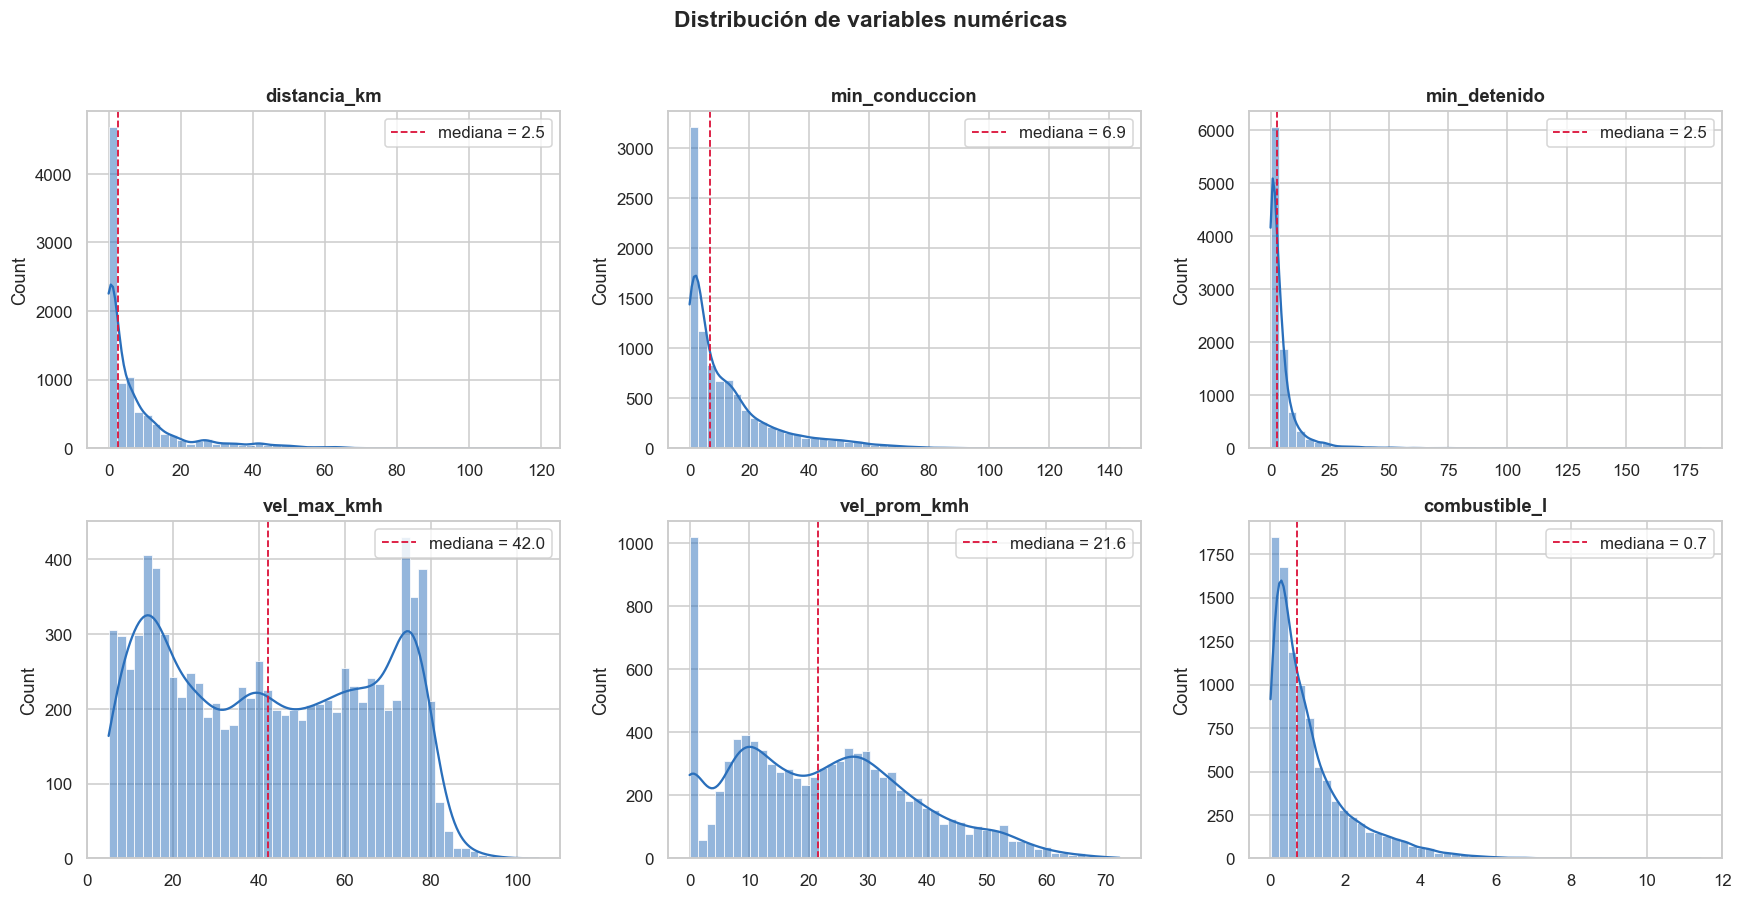

In [12]:
vars_hist = ["distancia_km", "min_conduccion", "min_detenido", "vel_max_kmh", "vel_prom_kmh", "combustible_l"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), vars_hist):
    sns.histplot(df_eda[c], bins=50, kde=True, ax=ax, color="#2a6fbb")
    ax.axvline(df_eda[c].median(), color="crimson", ls="--", lw=1.2, label=f"mediana = {df_eda[c].median():.1f}")
    ax.set_title(c)
    ax.set_xlabel("")
    ax.legend()
fig.suptitle("Distribución de variables numéricas", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

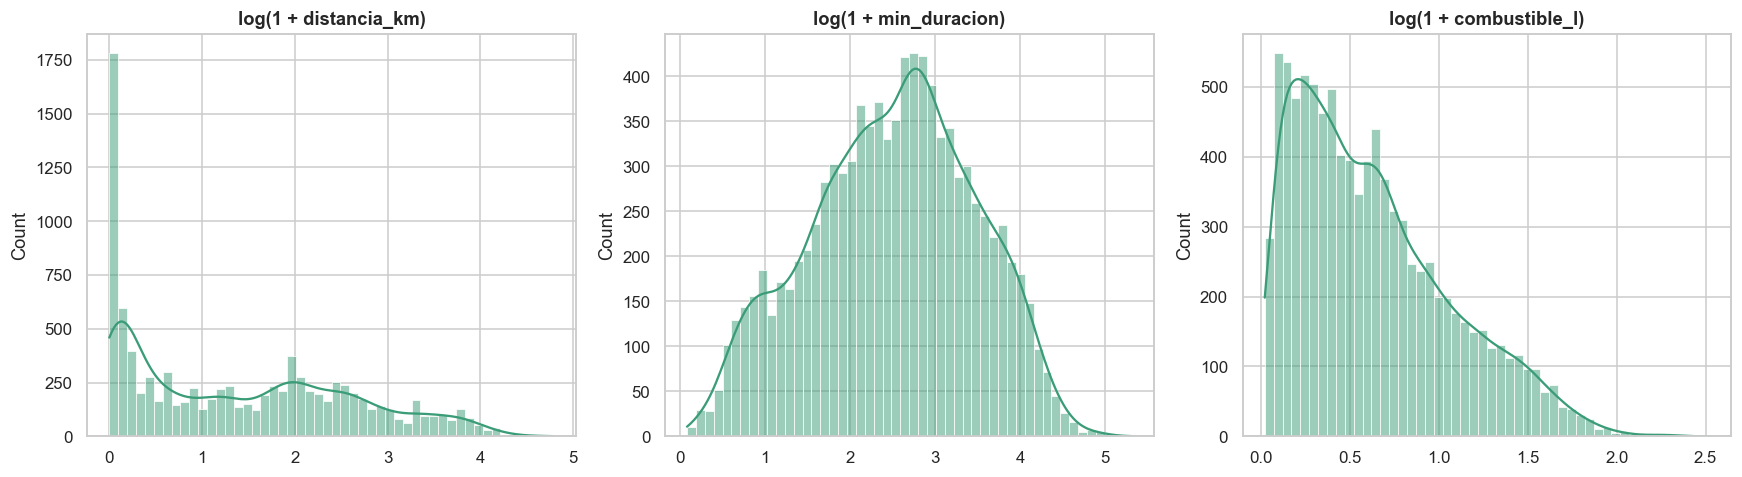

In [13]:
#Visualización de las variables con cola larga para que se vaen mejor en escala logarítmica
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["distancia_km", "min_duracion", "combustible_l"]):
    sns.histplot(np.log1p(df_eda[c].dropna()), bins=50, kde=True, ax=ax, color="#3b9c78")
    ax.set_title(f"log(1 + {c})")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 6.2 Boxplots y outliers

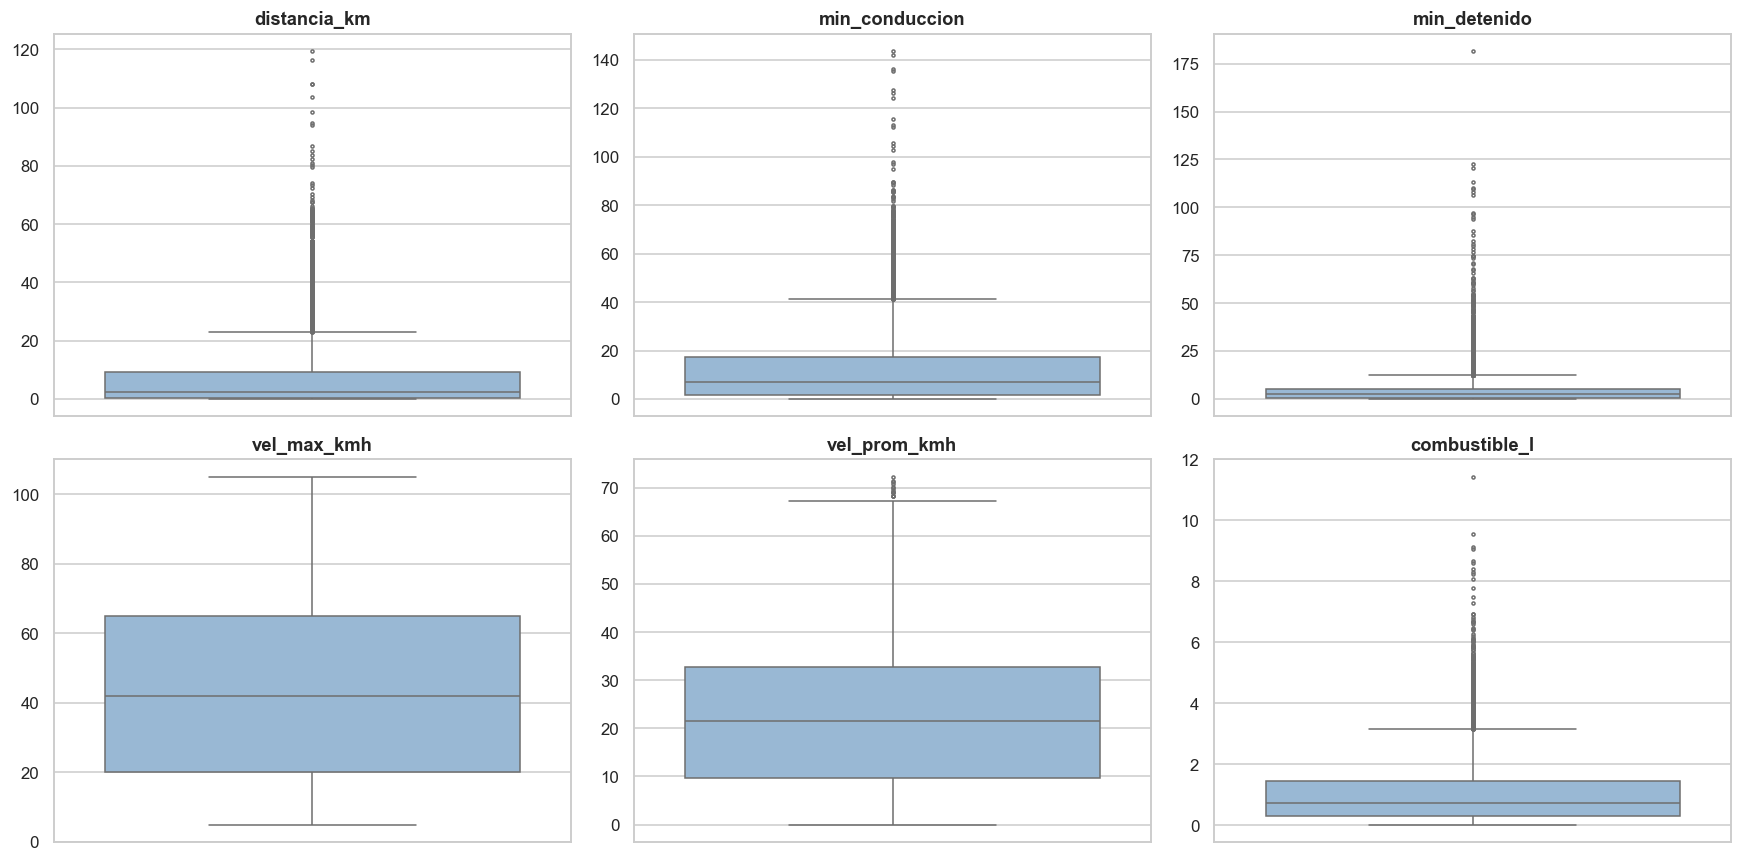

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), vars_hist):
    sns.boxplot(y=df_eda[c], ax=ax, color="#8fb8de", fliersize=2)
    ax.set_title(c)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 6.3 Variables categóricas

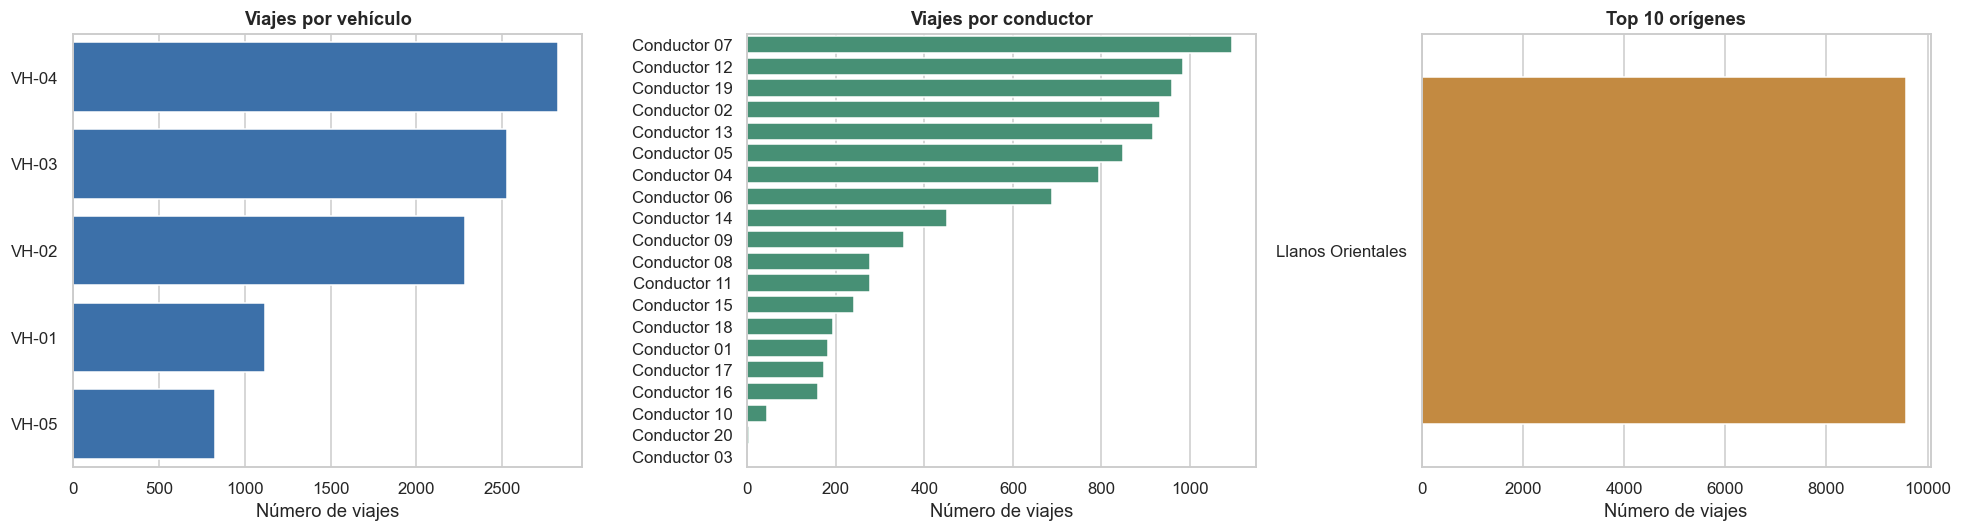

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

orden_v = df_eda["vehiculo"].value_counts().index
sns.countplot(data=df_eda, y="vehiculo", order=orden_v, ax=axes[0], color="#2a6fbb")
axes[0].set_title("Viajes por vehículo")

orden_c = df_eda["conductor"].value_counts().index
sns.countplot(data=df_eda, y="conductor", order=orden_c, ax=axes[1], color="#3b9c78")
axes[1].set_title("Viajes por conductor")

top_o = df_eda["origen"].value_counts().head(10).index
sns.countplot(data=df_eda[df_eda["origen"].isin(top_o)], y="origen", order=top_o, ax=axes[2], color="#d98c2b")
axes[2].set_title("Top 10 orígenes")

for ax in axes:
    ax.set_xlabel("Número de viajes")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

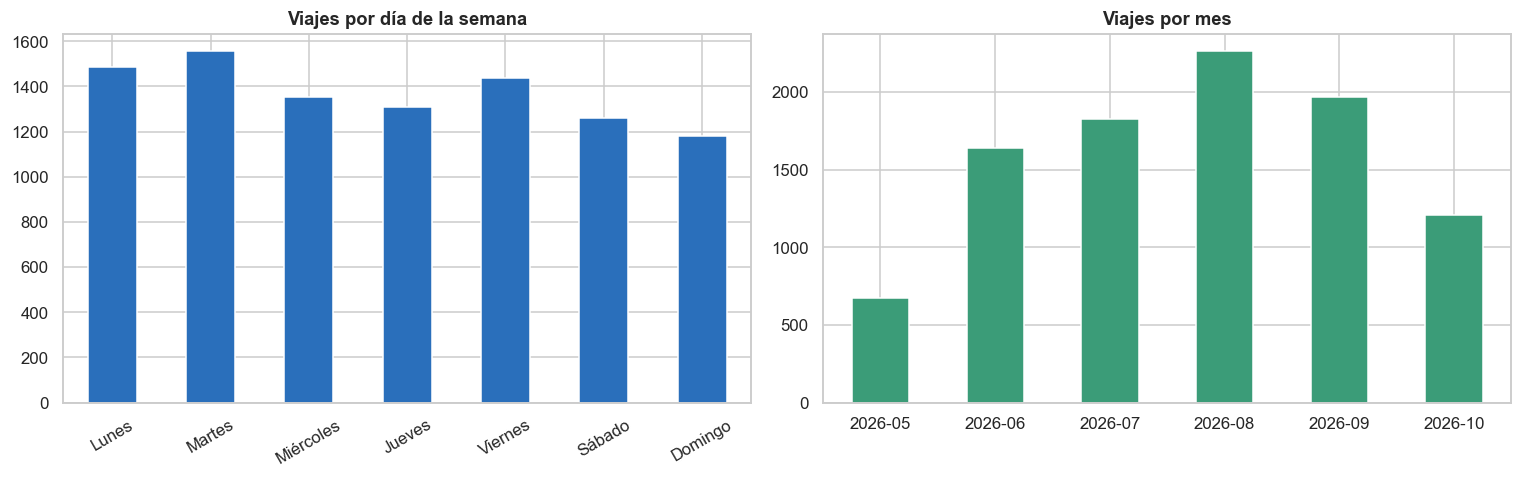

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
dist_dia = df_eda.groupby("dia_semana_n").size().rename(index=dias)
dist_dia.plot(kind="bar", ax=axes[0], color="#2a6fbb", rot=30)
axes[0].set_title("Viajes por día de la semana")
axes[0].set_xlabel("")

df_eda.groupby("mes").size().plot(kind="bar", ax=axes[1], color="#3b9c78", rot=0)
axes[1].set_title("Viajes por mes")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

### 6.4 Comportamiento en el tiempo

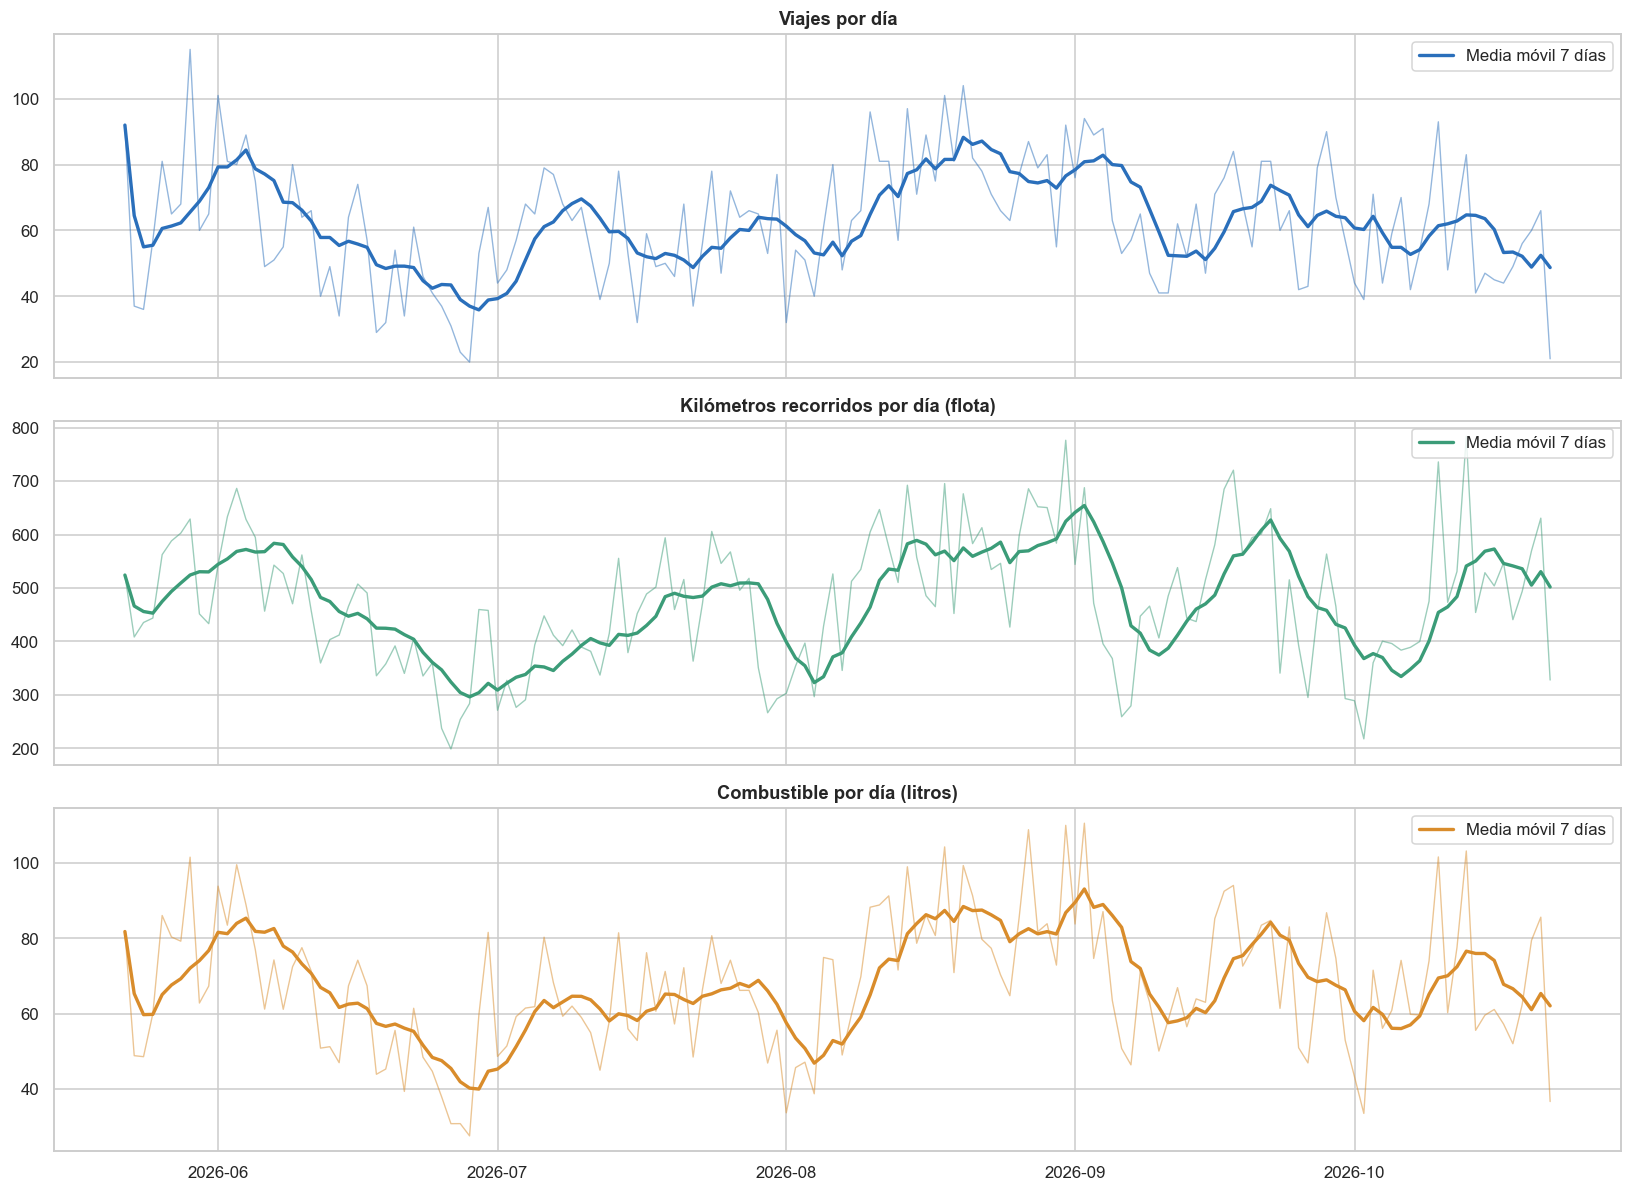

In [17]:
diario = df_eda.groupby("fecha").agg(viajes=("distancia_km", "size"),km=("distancia_km", "sum"),combustible_l=("combustible_l", "sum"),vehiculos_activos=("vehiculo", "nunique"),)

fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
for ax, (c, titulo, color) in zip(axes, [("viajes", "Viajes por día", "#2a6fbb"),("km", "Kilómetros recorridos por día (flota)", "#3b9c78"),("combustible_l", "Combustible por día (litros)", "#d98c2b"),]):
    ax.plot(diario.index, diario[c], lw=0.9, alpha=0.5, color=color)
    ax.plot(diario.index, diario[c].rolling(7, min_periods=1).mean(), lw=2.2, color=color, label="Media móvil 7 días")
    ax.set_title(titulo)
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

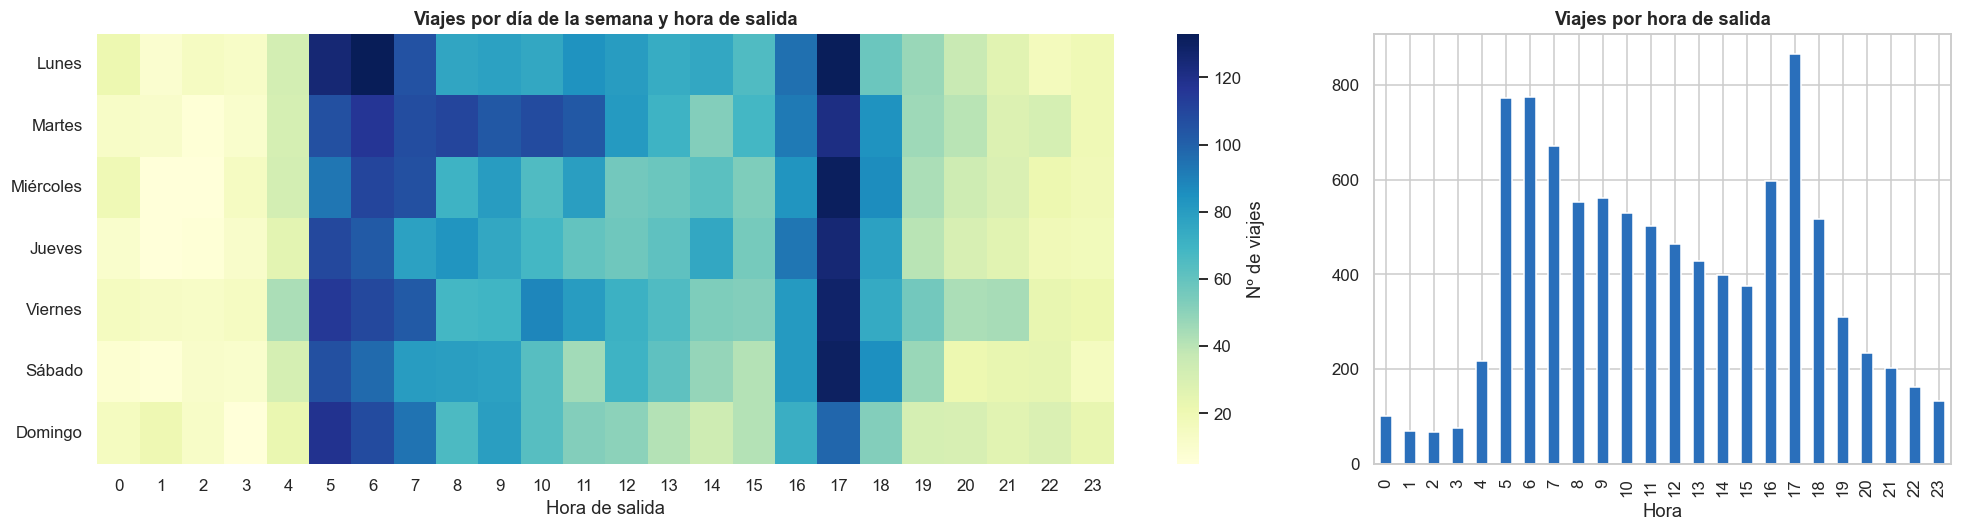

In [18]:
# Graficas para ver los viajes por hora del día y día de la semana
pivote = (df_eda.pivot_table(index="dia_semana_n", columns="hora_salida", values="distancia_km", aggfunc="size", fill_value=0)
          .rename(index=dias))

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [2.2, 1]})
sns.heatmap(pivote, cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "Nº de viajes"})
axes[0].set_title("Viajes por día de la semana y hora de salida")
axes[0].set_xlabel("Hora de salida")
axes[0].set_ylabel("")

df_eda.groupby("hora_salida").size().plot(kind="bar", ax=axes[1], color="#2a6fbb")
axes[1].set_title("Viajes por hora de salida")
axes[1].set_xlabel("Hora")
plt.tight_layout()
plt.show()

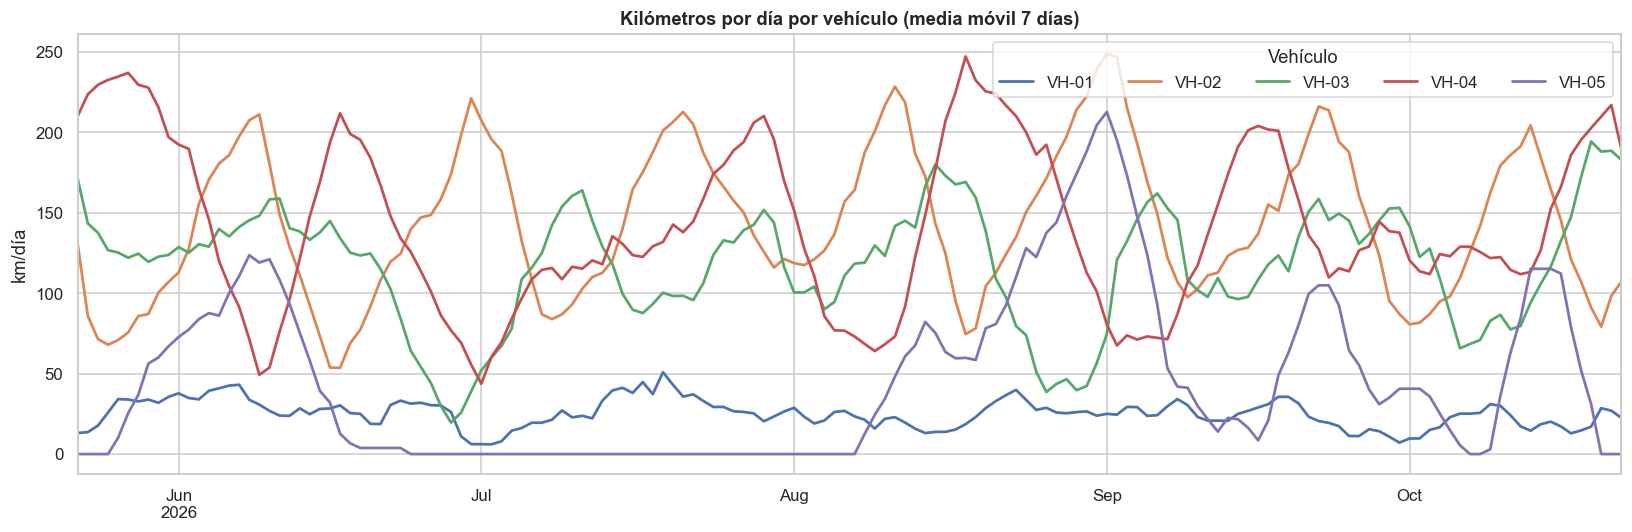

In [19]:
#Para ver la actividad diaria por vehículo (km por día)
km_veh = df_eda.pivot_table(index="fecha", columns="vehiculo", values="distancia_km", aggfunc="sum").fillna(0)
ax = km_veh.rolling(7, min_periods=1).mean().plot(figsize=(15, 5), lw=1.8)
ax.set_title("Kilómetros por día por vehículo (media móvil 7 días)")
ax.set_xlabel("")
ax.set_ylabel("km/día")
ax.legend(title="Vehículo", ncol=5)
plt.tight_layout()
plt.show()

### 6.5 Comparación entre vehículos y conductores

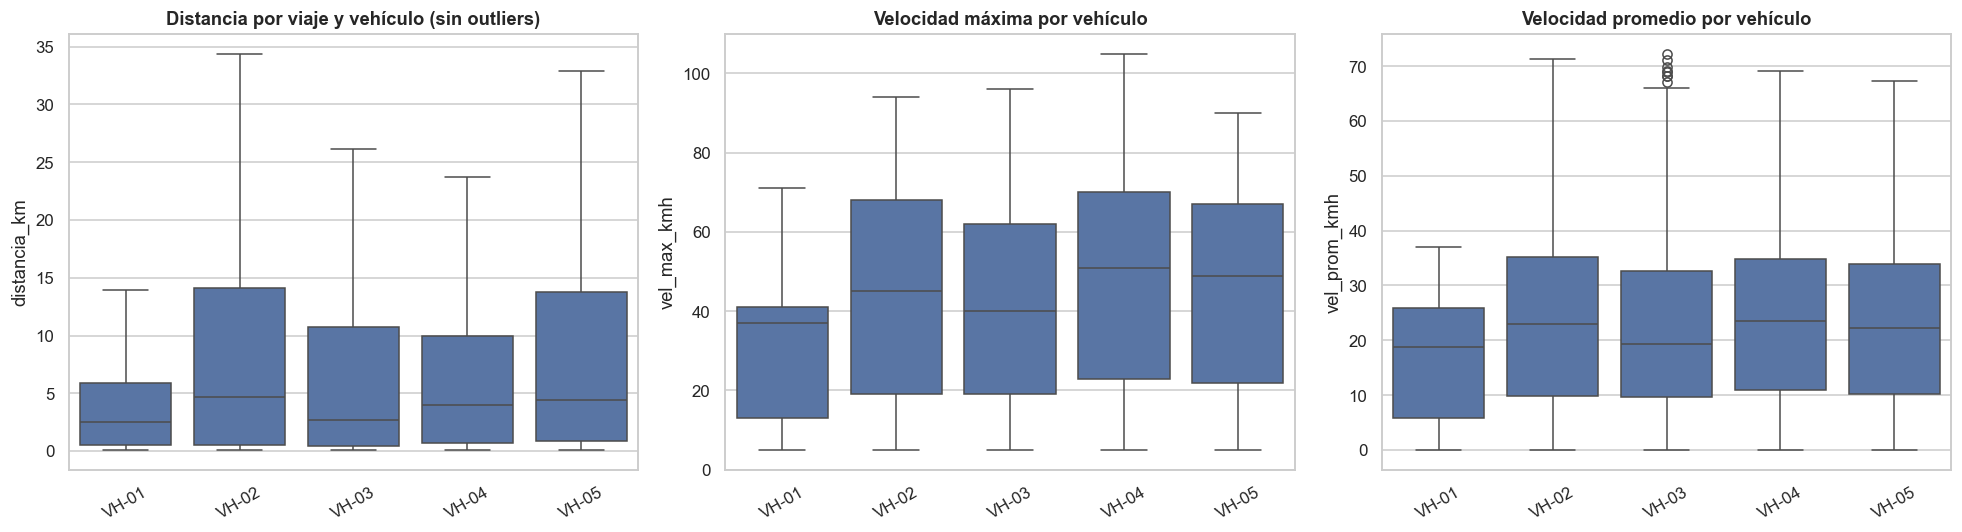

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
datos = df_eda[df_eda["distancia_km"] > 0]

sns.boxplot(data=datos, x="vehiculo", y="distancia_km", ax=axes[0], showfliers=False)
axes[0].set_title("Distancia por viaje y vehículo (sin outliers)")

sns.boxplot(data=df_eda, x="vehiculo", y="vel_max_kmh", ax=axes[1])
axes[1].set_title("Velocidad máxima por vehículo")

sns.boxplot(data=df_eda, x="vehiculo", y="vel_prom_kmh", ax=axes[2])
axes[2].set_title("Velocidad promedio por vehículo")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

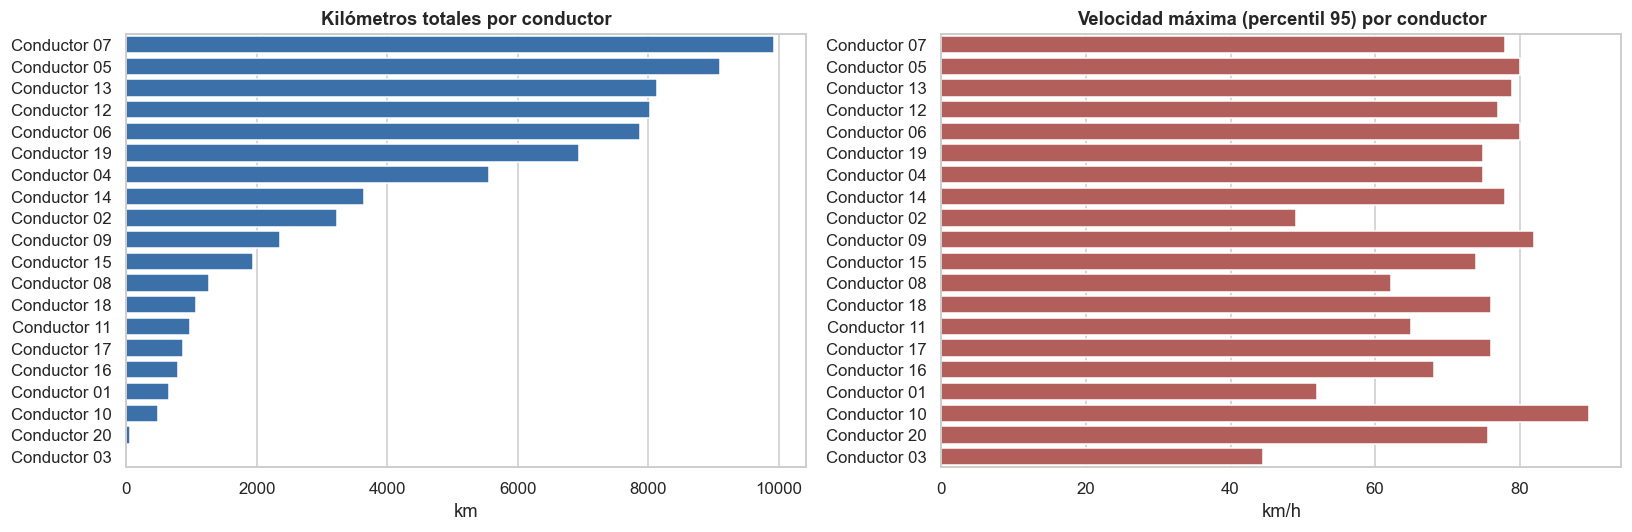

In [21]:
por_cond = df_eda.groupby("conductor").agg(viajes=("distancia_km", "size"),km_totales=("distancia_km", "sum"),vel_max_p95=("vel_max_kmh", lambda s: s.quantile(.95)),el_prom=("vel_prom_kmh", "mean"),).sort_values("km_totales", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=por_cond["km_totales"], y=por_cond.index, ax=axes[0], color="#2a6fbb")
axes[0].set_title("Kilómetros totales por conductor")
axes[0].set_xlabel("km")
axes[0].set_ylabel("")

sns.barplot(x=por_cond["vel_max_p95"], y=por_cond.index, ax=axes[1], color="#c0504d")
axes[1].set_title("Velocidad máxima (percentil 95) por conductor")
axes[1].set_xlabel("km/h")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

### 6.6 Relaciones entre variables

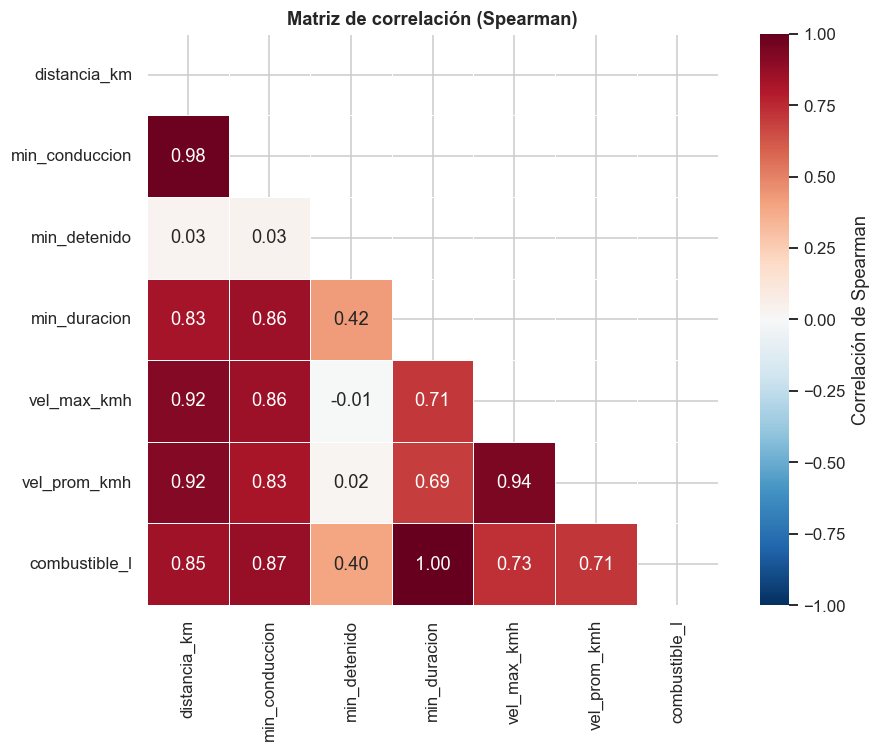

In [22]:
corr_cols = ["distancia_km", "min_conduccion", "min_detenido", "min_duracion","vel_max_kmh", "vel_prom_kmh", "combustible_l"]
corr = df_eda[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.5, square=True, ax=ax, cbar_kws={"label": "Correlación de Spearman"})
ax.set_title("Matriz de correlación (Spearman)")
plt.tight_layout()
plt.show()

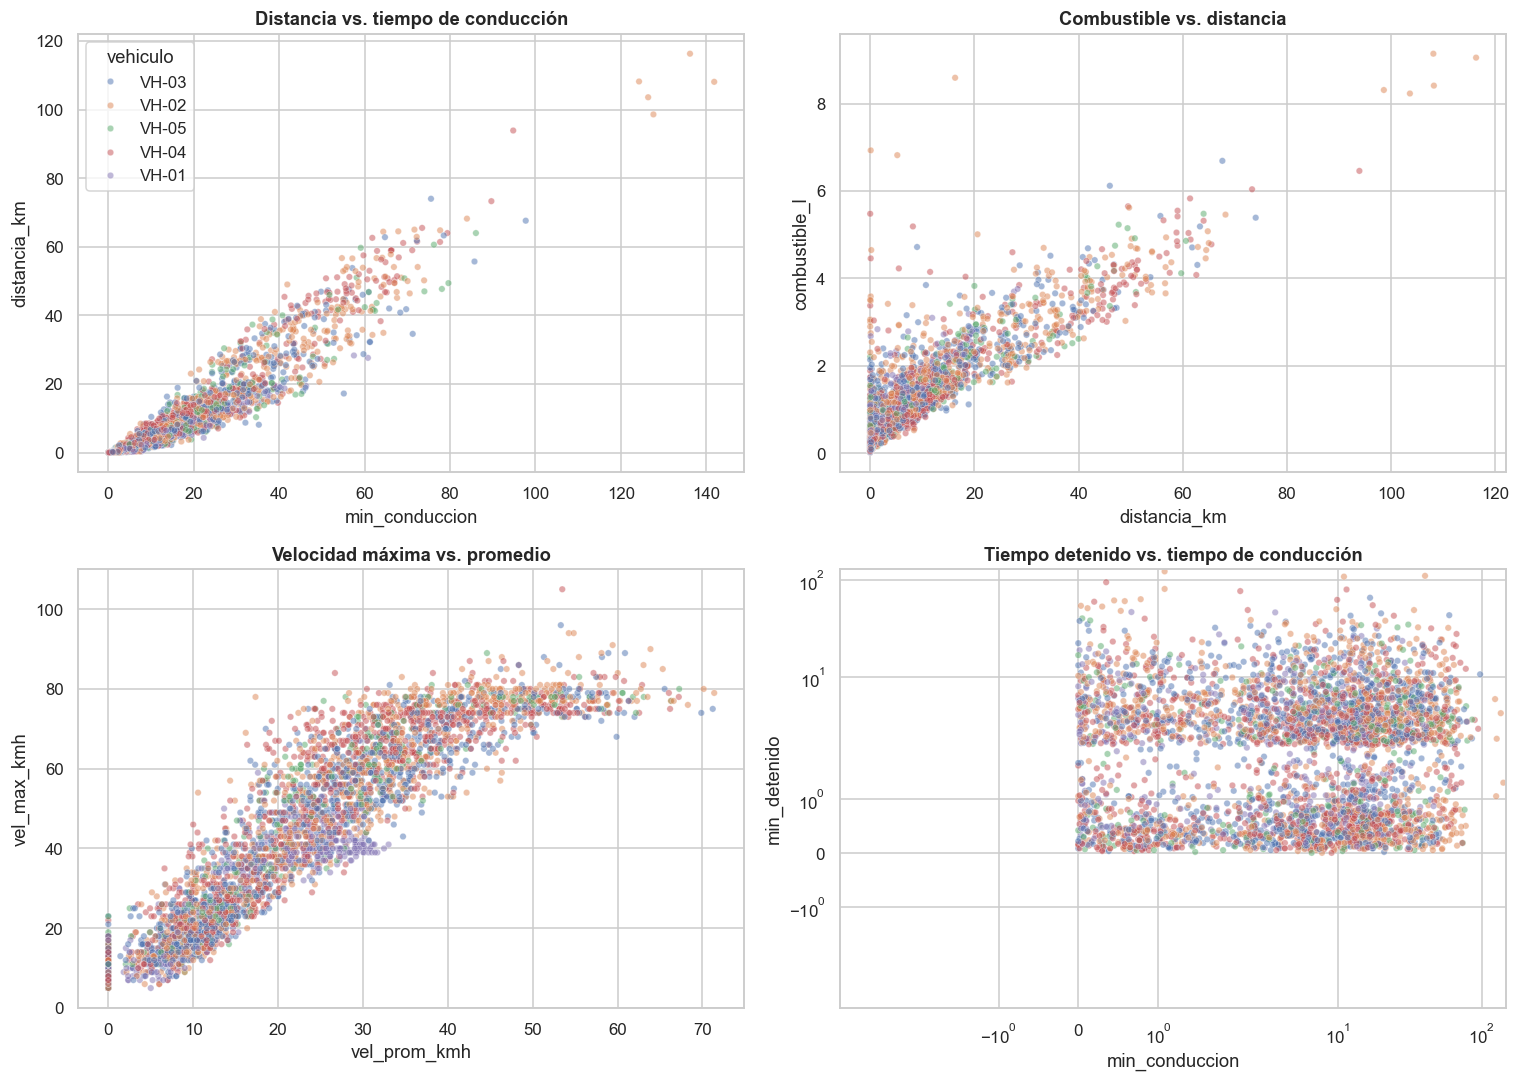

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
muestra = df_eda.sample(min(4000, len(df_eda)), random_state=42)

sns.scatterplot(data=muestra, x="min_conduccion", y="distancia_km", hue="vehiculo", alpha=.5, s=18, ax=axes[0, 0])
axes[0, 0].set_title("Distancia vs. tiempo de conducción")

sns.scatterplot(data=muestra, x="distancia_km", y="combustible_l", hue="vehiculo", alpha=.5, s=18, ax=axes[0, 1], legend=False)
axes[0, 1].set_title("Combustible vs. distancia")

sns.scatterplot(data=muestra, x="vel_prom_kmh", y="vel_max_kmh", hue="vehiculo", alpha=.5, s=18, ax=axes[1, 0], legend=False)
axes[1, 0].set_title("Velocidad máxima vs. promedio")

sns.scatterplot(data=muestra, x="min_conduccion", y="min_detenido", hue="vehiculo", alpha=.5, s=18, ax=axes[1, 1], legend=False)
axes[1, 1].set_title("Tiempo detenido vs. tiempo de conducción")
axes[1, 1].set_xscale("symlog")
axes[1, 1].set_yscale("symlog")

plt.tight_layout()
plt.show()

#### **Analisis preliminar**

* Los histogramas y boxplots confirman lo que mostraba la tabla: distancia_km, los tiempos de conducción, detenido y duración, y el combustible tienen una cola larga a la derecha. Hay muchísimos viajes cortos y pocos muy largos, por lo que fue útil verlos también en escala logarítmica. Las velocidades se distribuyen de forma mucho más pareja. Los gráficos de categorías muestran que VH-04 (2.824 viajes), VH-03 (2.525) y VH-02 (2.286) concentran la mayor parte de la actividad, mientras que VH-01 (1.116) y VH-05 (829) tienen mucho menos. En el boxplot por vehículo, VH-01 se ve con viajes más cortos y menor velocidad, y VH-02 y VH-05 tienen los viajes más largos entre los cuartiles superiores. VH-04 alcanza la velocidad máxima más alta (105 km/h).

* En el tiempo, cada día hubo al menos una camioneta en operación entre el 22/05/2026 y el 22/10/2026. Las series diarias de viajes, kilómetros y combustible, con su media móvil de 7 días, permiten ver la tendencia sin el ruido del día a día. El mapa de calor por día de la semana y hora de salida muestra que el pico de viajes ocurre a las 17:00 h y que el martes es el día con más viajes. En kilómetros totales, VH-02 lidera con 22.159 km, seguido de VH-04 (21.714 km) y VH-03 (18.142 km). VH-05 solo estuvo activo 67 días, y por eso acumula 7.008 km.

* En las relaciones entre variables, la matriz de correlación de Spearman y los gráficos de dispersión muestran una asociación fuerte entre distancia y combustible (aproximadamente de 0,85). También se ve que a más tiempo de conducción, más distancia recorrida. En el consumo, al filtrar los viajes de al menos 1 km, la mediana es de 15,0 L/100 km y VH-01 destaca con el consumo global más alto (≈22 L/100 km frente a 13–15 en el resto). Eso sugiere un uso más urbano o con mucho tiempo en ralentí, aunque es una hipótesis que habría que validar.


## 7. Hallazgos principales

In [24]:
# Resumen automático calculado desde los datos
dias_act = df_eda["fecha"].nunique()
print(f"• {len(df_eda):,} viajes de {df_eda['vehiculo'].nunique()} vehículos y {df_eda['conductor'].nunique()} conductores, "
      f"entre {df_eda['fecha'].min():%d/%m/%Y} y {df_eda['fecha'].max():%d/%m/%Y} ({dias_act} días con actividad).")
print(f"• Distancia total: {df_eda['distancia_km'].sum():,.0f} km | mediana por viaje: {df_eda['distancia_km'].median():.1f} km | máxima: {df_eda['distancia_km'].max():.1f} km.")
print(f"• {(df_eda['distancia_km'] < 1).mean():.1%} de los viajes son menores a 1 km (movimientos cortos / maniobras).")
print(f"• Vehículo con más km: {resumen_veh['km_totales'].idxmax()} ({resumen_veh['km_totales'].max():,.0f} km).")
print(f"• Hora pico de salida: {df_eda['hora_salida'].value_counts().idxmax()}:00 h | día con más viajes: {dist_dia.idxmax()}.")
print(f"• Velocidad máxima registrada: {df_eda['vel_max_kmh'].max()} km/h | % de viajes con vel. máx > 80 km/h: {(df_eda['vel_max_kmh'] > 80).mean():.1%}.")
print(f"• Consumo mediano (viajes ≥ 1 km): {df_cons['consumo_l_100km'].median():.1f} L/100 km.")
print(f"• Correlación (Spearman) distancia–combustible: {corr.loc['distancia_km', 'combustible_l']:.2f}.")

• 9,580 viajes de 5 vehículos y 20 conductores, entre 22/05/2026 y 22/10/2026 (154 días con actividad).
• Distancia total: 72,917 km | mediana por viaje: 2.5 km | máxima: 119.4 km.
• 38.8% de los viajes son menores a 1 km (movimientos cortos / maniobras).
• Vehículo con más km: VH-02 (22,159 km).
• Hora pico de salida: 17:00 h | día con más viajes: Martes.
• Velocidad máxima registrada: 105 km/h | % de viajes con vel. máx > 80 km/h: 1.7%.
• Consumo mediano (viajes ≥ 1 km): 15.0 L/100 km.
• Correlación (Spearman) distancia–combustible: 0.85.


### Conclusiones

**Calidad de los datos**
- El archivo trae 29 columnas y ninguna está completamente vacía, pero 8 son constantes (`SiteName`, `TimeZone1`, `TimeZone2`, `TimeZone`, `DepartFrom`, `ArriveAt`, `TripType` y `NrOfVisits`): un solo sitio, una sola zona horaria, el mismo origen y destino ("Llanos Orientales") y un solo tipo de viaje. Tras eliminar 9 filas duplicadas quedan 9.580 viajes con información útil.
- Los datos ya vienen anonimizados: los vehículos aparecen como VH-01 a VH-05 y los conductores como "Conductor 01" a "Conductor 20".


**Comportamiento de la flota**
- El 38,8 % de los viajes recorre menos de 1 km (1.020 con distancia 0): son movimientos cortos o maniobras dentro de un mismo sitio. Por eso la mediana por viaje es solo 2,5 km, mientras la media es 7,6 km y el máximo 119,4 km.
- Las distancias, los tiempos y el combustible tienen cola larga a la derecha (asimetría entre 2,0 y 2,7; `min_detenido` llega a 6,3). Las velocidades máximas, en cambio, son casi simétricas.
- VH-02, VH-03 y VH-04 concentran la operación (entre 18.000 y 22.000 km cada uno, con 123–144 km por día activo). VH-05 solo estuvo activo 67 días y VH-01 tiene un uso mucho menor (≈29 km por día activo).
- La actividad es continua durante los 154 días del periodo (22/05/2026 a 22/10/2026), con un pico de salidas a las 17:00 h y el martes como día con más viajes.

**Consumo y velocidad**
- El consumo calculado (`consumo_l_100km`) no es confiable en trayectos muy cortos: llega a 6.930 L/100 km porque divide entre una distancia casi nula. Filtrando viajes de al menos 1 km, la mediana es de 15,0 L/100 km.
- VH-01 muestra el consumo global más alto (≈22 L/100 km frente a 13–15 en el resto), lo que sugiere un uso más urbano o con mucho tiempo en ralentí; es una hipótesis que habría que validar con más contexto.
- Distancia y combustible están fuertemente relacionados (Spearman ≈ 0,85). La velocidad máxima registrada es 105 km/h y solo el 1,7 % de los viajes supera los 80 km/h.

**Pasos sugeridos para un modelo o pipeline**
- Excluir las columnas constantes y los identificadores técnicos (`AssetID`, `AssetExtra2`). `AssetName2` ya viene anonimizado y se usa como `conductor`.
- Tratar `min_en_destino` con cuidado: tiene valores extremos (hasta ~75.000 min) que corresponden a largos periodos sin actividad.
- Calcular el consumo solo para viajes de al menos 1 km, o trabajar con combustible y distancia por separado.


## 8. Versiones del entorno para MLOps

En la celda siguiente se documenta todo lo necesario para reproducir este análisis: versión de Python, sistema operativo, hardware, versión de cada librería importada en el notebook, la huella (hash) del dataset y un `requirements.txt` con todo el entorno.

Si se desea, se pueden generar los siguientes archivos que genera:
- `requirements.txt` : entorno completo (`pip freeze`).
- `requirements_notebook.txt` : solo las librerías que usa este notebook, con versión fija.
- `environment_info.json` : Python, SO, hardware, librerías y huella del dataset, en un formato fácil de leer desde un pipeline.

In [25]:
import sys, platform, json, hashlib, subprocess, os, importlib, importlib.metadata as md
from datetime import datetime

#Información del sistema 
sistema = {
    "fecha_ejecucion": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.replace("\n", " "),
    "python_version": platform.python_version(),
    "implementacion": platform.python_implementation(),
    "ejecutable": sys.executable,
    "sistema_operativo": platform.system(),
    "version_so": platform.version(),
    "release_so": platform.release(),
    "arquitectura": platform.machine(),
    "procesador": platform.processor() or "n/d",
    "cpu_nucleos": os.cpu_count(),
}

#Librerías importadas en ESTE notebook 
# Se detectan automáticamente los módulos cargados en la sesión que provienen de paquetes instalados.
mapa_modulo_a_paquete = importlib.metadata.packages_distributions()
modulos_usados = {m.split(".")[0] for m in sys.modules if not m.startswith("_")}
stdlib = set(sys.stdlib_module_names)

libs_notebook = {}
for mod in sorted(modulos_usados - stdlib):
    for paquete in mapa_modulo_a_paquete.get(mod, []):
        try:
            libs_notebook[paquete] = md.version(paquete)
        except md.PackageNotFoundError:
            pass

#Se contemplan Solo las librerías que importamos de forma directa (excluye dependencias internas)
directas = ["pandas", "numpy", "matplotlib", "seaborn", "scipy"]
libs_directas = {p: md.version(p) for p in directas}

#Entorno completo (pip freeze) 
try:
    freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"],
                            capture_output=True, text=True, check=True).stdout.strip().splitlines()
except Exception:
    freeze = sorted(f"{d.metadata['Name']}=={d.version}" for d in md.distributions())

#Huella del dataset (trazabilidad de datos) 
sha = hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest()
dataset = {
    "archivo": Path(DATA_PATH).name,
    "sha256": sha,
    "filas_originales": int(dataframe.shape[0]),
    "columnas_originales": int(dataframe.shape[1]),
    "filas_tras_limpieza": int(df_eda.shape[0]),
    "columnas_tras_limpieza": int(df_eda.shape[1]),
    "periodo": [str(df_eda["fecha"].min().date()), str(df_eda["fecha"].max().date())],
}

#Se deja esta parte comentada debido a que es opccional para que la persona que vaya a replicar, mire si genera los archivos o no
 
#Guardar archivos 
# Path("requirements.txt").write_text("\n".join(freeze) + "\n", encoding="utf-8")
# Path("requirements_notebook.txt").write_text(
#     "\n".join(f"{p}=={v}" for p, v in sorted(libs_directas.items())) + "\n", encoding="utf-8")
# info = {"sistema": sistema, "librerias_directas": libs_directas,
#         "librerias_detectadas_en_sesion": libs_notebook, "dataset": dataset}
# Path("environment_info.json").write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding="utf-8")

# #Mostrar resultados 
# print("=" * 70)
# print("SISTEMA")
# print("=" * 70)
# for k, v in sistema.items():
#     print(f"{k:<20}: {v}")

# print("\n" + "=" * 70)
# print("LIBRERÍAS USADAS DIRECTAMENTE EN ESTE NOTEBOOK")
# print("=" * 70)
# for p, v in libs_directas.items():
#     print(f"{p:<20}: {v}")

# print("\n" + "=" * 70)
# print(f"TODAS LAS LIBRERÍAS DETECTADAS EN LA SESIÓN ({len(libs_notebook)})")
# print("=" * 70)
# for p, v in sorted(libs_notebook.items()):
#     print(f"{p:<28}: {v}")

# print("\n" + "=" * 70)
# print(f"ENTORNO COMPLETO INSTALADO: {len(freeze)} paquetes (ver requirements.txt)")
# print("=" * 70)
# print("\nDATASET")
# for k, v in dataset.items():
#     print(f"{k:<24}: {v}")

# print("\nArchivos generados: requirements.txt, requirements_notebook.txt, environment_info.json")